# From proposal to result: a CNN trained on the robot's own world

The CIFAR-10 model cannot recognise the arena's objects (the blocks came out as *airplane*), so the report proposes training on images from Webots itself.
This notebook does that on a small scale.

**Task.** Tell **blocks** from same-coloured **balls** and **cylinders**, and from empty **background**.
Every object comes in red, green or blue, so the HSV colour detector fires on all of them and colour carries no information about shape.
HSV says *"something red"*; the CNN has to say *"a block, not a ball"*.

**Data.** `webots_project/worlds/shape_dataset.wbt` and its supervisor controller `shape_dataset_collector` place 3 blocks, 3 balls and 3 cylinders at random, with random colours, sizes and light levels (domain randomisation [Tobin et al., 2017]), teleport the e-puck to many viewpoints and **label every crop automatically** from the objects' known 3-D positions.

**Three test sets, all from layouts never used in training** (train seeds 0–79, test seeds 100000–100024):
* `train`: 80 layouts; layouts 70–79 are held out as the validation set (whole layouts, so no near-duplicate views leak across).
* `test`: 25 new layouts, cropped like the training data (projected box with detector-like jitter, then the robot's `square_crop`).
* `test_hsv`: the same 25 layouts, but every object is cropped by **the robot's own HSV detector**, exactly as on the robot. This checks that the model has not learned a shortcut from how the training crops were made. (Objects only: the HSV detector never crops empty background.)

"Unseen layouts" means new scenes from the same simulator generator; it does not show transfer to a real camera.
Crops from one layout are correlated (about 40 views of the same 9 objects), so confidence intervals are **bootstrapped over test layouts**, not over crops, and every method is trained with **three seeds**.

In [1]:
import csv, pathlib, sys, time
import numpy as np, cv2 as cv, matplotlib.pyplot as plt, tensorflow as tf, keras
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, f1_score, recall_score

sys.path.insert(0, str(pathlib.Path("../webots_project/controllers/colour_detector").resolve()))
import vision  # the robot's own HSV detector

CLASSES = ["block", "ball", "cylinder", "background"]
ROOT = pathlib.Path("webots_shapes"); OUT = pathlib.Path("results/webots_shapes"); OUT.mkdir(parents=True, exist_ok=True)
SEEDS = (42, 1, 2)

def load(split):
    rows = list(csv.DictReader(open(ROOT / split / "labels.csv")))
    x = np.stack([cv.imread(str(ROOT / r["file"]))[:, :, ::-1] for r in rows]).astype("float32") / 255.0  # BGR->RGB, 0-1
    y = np.array([CLASSES.index(r["class"]) for r in rows])
    layout = np.array([int(r["layout"]) for r in rows])
    return x, y, layout, rows

x_all, y_all, lay_all, rows_all = load("train")
x_test, y_test, lay_test, rows_test = load("test")
x_hsv, y_hsv, lay_hsv, rows_hsv = load("test_hsv")
val_mask = lay_all >= 70
x_train, y_train, x_val, y_val = x_all[~val_mask], y_all[~val_mask], x_all[val_mask], y_all[val_mask]
for name, y in [("train", y_train), ("val", y_val), ("test", y_test), ("test_hsv", y_hsv)]:
    print(f"{name:<8} {len(y):5d} images  " + "  ".join(f"{c} {int((y == i).sum())}" for i, c in enumerate(CLASSES)))

# Label-quality check: how well the projected box agrees with the HSV detector's blob of the same colour.
# Low values are expected when another object of that colour is bigger in the frame (the detector
# reports the largest blob of each colour), so this is a rough check, not an error rate.
iou = np.array([float(r["hsv_iou"]) for r in rows_all if r["hsv_iou"]])
print(f"\nprojected box vs HSV blob IoU (train objects): median {np.median(iou):.2f}, "
      f"{(iou >= 0.5).mean():.0%} of crops >= 0.5, {(iou < 0.1).mean():.0%} < 0.1 (blob is another object)")

train     3419 images  block 741  ball 917  cylinder 898  background 863
val        458 images  block 110  ball 129  cylinder 117  background 102
test      1243 images  block 311  ball 309  cylinder 310  background 313
test_hsv   707 images  block 212  ball 223  cylinder 272  background 0

projected box vs HSV blob IoU (train objects): median 0.64, 72% of crops >= 0.5, 18% < 0.1 (blob is another object)


## Classical baselines (no deep learning)

Two hand-made feature sets, each tuned on the validation layouts:
* **HSV shape features + random forest**: the robot's HSV mask of the crop, then the largest blob's area, aspect ratio, extent (area / box area), solidity (area / convex-hull area) and circularity.
* **HOG + linear SVM**: histograms of oriented gradients [Dalal and Triggs, 2005], a standard pre-deep-learning shape descriptor, on the grey-scale crop.

In [2]:
def shape_features(rgb01):
    bgr = (rgb01[:, :, ::-1] * 255).astype("uint8")
    hsv = cv.cvtColor(cv.GaussianBlur(bgr, (3, 3), 0), cv.COLOR_BGR2HSV)
    mask = np.zeros(hsv.shape[:2], np.uint8)
    for colour in vision.HSV_RANGES:
        mask |= vision.colour_mask(hsv, colour)
    contours, _ = cv.findContours(mask, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
    if not contours:
        return [0, 0, 0, 0, 0]
    c = max(contours, key=cv.contourArea); area = cv.contourArea(c)
    x, y, w, h = cv.boundingRect(c); hull = cv.contourArea(cv.convexHull(c)); perim = cv.arcLength(c, True)
    return [area / 1024, w / max(h, 1), area / max(w * h, 1), area / max(hull, 1e-6), 4 * np.pi * area / max(perim ** 2, 1e-6)]

def hog_features(rgb01, cell=8, bins=9):
    """Histogram of oriented gradients (Dalal and Triggs): unsigned gradient orientation in
    9 bins per 8x8 cell, 2x2-cell blocks with L2-Hys normalisation -> 324 values for 32x32."""
    g = cv.cvtColor((rgb01 * 255).astype("uint8"), cv.COLOR_RGB2GRAY).astype("float32")
    gx, gy = cv.Sobel(g, cv.CV_32F, 1, 0, ksize=1), cv.Sobel(g, cv.CV_32F, 0, 1, ksize=1)
    mag, ang = np.hypot(gx, gy), np.rad2deg(np.arctan2(gy, gx)) % 180
    n = g.shape[0] // cell
    hist = np.zeros((n, n, bins), np.float32)
    idx = np.minimum((ang / (180 / bins)).astype(int), bins - 1)
    for i in range(n):
        for j in range(n):
            sl = (slice(i * cell, (i + 1) * cell), slice(j * cell, (j + 1) * cell))
            hist[i, j] = np.bincount(idx[sl].ravel(), weights=mag[sl].ravel(), minlength=bins)
    out = []
    for i in range(n - 1):
        for j in range(n - 1):
            v = hist[i:i + 2, j:j + 2].ravel()
            v = np.minimum(v / (np.linalg.norm(v) + 1e-6), 0.2)
            out.append(v / (np.linalg.norm(v) + 1e-6))
    return np.concatenate(out)

feats = {}
for name, fn in [("shape", shape_features), ("hog", hog_features)]:
    feats[name] = {s: np.array([fn(x) for x in xs]) for s, xs in
                   [("train", x_train), ("val", x_val), ("test", x_test), ("hsv", x_hsv)]}

def fit_rf(seed):
    # Hyper-parameters chosen on the validation layouts.
    best = None
    for depth in (None, 10, 20):
        for leaf in (1, 3, 5):
            m = RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_leaf=leaf, random_state=seed)
            m.fit(feats["shape"]["train"], y_train)
            acc = (m.predict(feats["shape"]["val"]) == y_val).mean()
            if best is None or acc > best[0]:
                best = (acc, m, depth, leaf)
    return best

def fit_hog_svm(seed):
    best = None
    for c in (0.01, 0.1, 1.0, 10.0):
        m = make_pipeline(StandardScaler(), LinearSVC(C=c, max_iter=20000, random_state=seed))
        m.fit(feats["hog"]["train"], y_train)
        acc = (m.predict(feats["hog"]["val"]) == y_val).mean()
        if best is None or acc > best[0]:
            best = (acc, m, c)
    return best

## Three CNNs

* **Frozen CIFAR features + new head**: the CIFAR-10 network up to global average pooling, unchanged; only a new 4-class head is trained.
* **Fine-tuned**: the same, then all layers trained at a low learning rate (transfer learning [Yosinski et al., 2014]).
* **From scratch**: the same architecture with random weights, to measure what the CIFAR-10 pre-training is worth.

Every model is built right after `keras.utils.set_random_seed(seed)`, so each run is reproducible on its own.
Early stopping restores the weights with the lowest validation loss; the validation accuracy printed is the one *at those weights*.

In [3]:
GAP = "global_average_pooling2d"

def head(features, name):
    h = keras.layers.Dense(64, activation="relu", name=f"{name}_dense")(features)
    h = keras.layers.Dropout(0.3, name=f"{name}_drop")(h)
    return keras.layers.Dense(len(CLASSES), name=f"{name}_logits")(h)

def compile_fit(model, lr, epochs, patience=6, start_from_epoch=0):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True, start_from_epoch=start_from_epoch)
    hist = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=epochs, batch_size=64, callbacks=[stop], verbose=0)
    return len(hist.history["loss"])

def predict(model, x):
    return np.argmax(model.predict(x, verbose=0, batch_size=256), axis=1)

def build_frozen(seed):
    keras.utils.set_random_seed(seed)
    cifar = keras.models.load_model("results/models/cifar10_cnn.keras")
    base = keras.Model(cifar.input, cifar.get_layer(GAP).output, name="cifar_features"); base.trainable = False
    inp = keras.Input((32, 32, 3)); m = keras.Model(inp, head(base(inp, training=False), "frozen"), name="frozen")
    return m, compile_fit(m, 1e-3, 60)

def build_finetuned(seed):
    keras.utils.set_random_seed(seed)
    cifar = keras.models.load_model("results/models/cifar10_cnn.keras")
    base = keras.Model(cifar.input, cifar.get_layer(GAP).output, name="cifar_features_ft"); base.trainable = False
    inp = keras.Input((32, 32, 3)); m = keras.Model(inp, head(base(inp), "ft"), name="finetuned")
    n = compile_fit(m, 1e-3, 10)               # warm up the new head
    base.trainable = True
    return m, n + compile_fit(m, 1e-4, 60)     # then train every layer at a low learning rate

def build_scratch(seed):
    # With fresh batch-normalisation statistics the validation accuracy stays at chance for the
    # first ~6 epochs while the running means and variances settle, then climbs quickly; early
    # stopping is therefore not allowed to act before epoch 15 (otherwise the baseline is cut short).
    keras.utils.set_random_seed(seed)
    cifar = keras.models.load_model("results/models/cifar10_cnn.keras")
    base = keras.models.clone_model(cifar)  # same architecture, new random weights
    feat = keras.Model(base.input, base.get_layer(GAP).output, name="scratch_features")
    inp = keras.Input((32, 32, 3)); m = keras.Model(inp, head(feat(inp), "scr"), name="scratch")
    return m, compile_fit(m, 1e-3, 100, patience=10, start_from_epoch=15)

## Train every method with three seeds

In [4]:
runs = {}  # (method, seed) -> dict(pred_test, pred_hsv, val_acc, model)
t_all = time.time()
for seed in SEEDS:
    acc, rf, depth, leaf = fit_rf(seed)
    runs[("HSV shape features + random forest", seed)] = dict(val_acc=acc, model=rf,
        pred_test=rf.predict(feats["shape"]["test"]), pred_hsv=rf.predict(feats["shape"]["hsv"]))
    acc, svm, c = fit_hog_svm(seed)
    runs[("HOG + linear SVM", seed)] = dict(val_acc=acc, model=svm,
        pred_test=svm.predict(feats["hog"]["test"]), pred_hsv=svm.predict(feats["hog"]["hsv"]))
    for name, build in [("CNN: frozen CIFAR features", build_frozen), ("CNN: fine-tuned from CIFAR", build_finetuned),
                        ("CNN: from scratch", build_scratch)]:
        t0 = time.time(); m, epochs = build(seed)
        runs[(name, seed)] = dict(val_acc=(predict(m, x_val) == y_val).mean(), model=m,
                                  pred_test=predict(m, x_test), pred_hsv=predict(m, x_hsv))
        print(f"seed {seed:2d}  {name:<28} epochs {epochs:3d}  val acc {runs[(name, seed)]['val_acc']:.1%}  ({time.time() - t0:.0f} s)")
    print(f"seed {seed:2d}  random forest: depth={depth}, min leaf={leaf}; HOG-SVM: C={c}")
print(f"total {time.time() - t_all:.0f} s")

seed 42  CNN: frozen CIFAR features   epochs  51  val acc 92.6%  (47 s)


seed 42  CNN: fine-tuned from CIFAR   epochs  48  val acc 99.8%  (128 s)


seed 42  CNN: from scratch            epochs  29  val acc 100.0%  (94 s)
seed 42  random forest: depth=None, min leaf=1; HOG-SVM: C=0.1


seed  1  CNN: frozen CIFAR features   epochs  60  val acc 92.8%  (61 s)


seed  1  CNN: fine-tuned from CIFAR   epochs  60  val acc 99.8%  (158 s)


seed  1  CNN: from scratch            epochs  26  val acc 99.6%  (80 s)
seed  1  random forest: depth=None, min leaf=1; HOG-SVM: C=0.1


seed  2  CNN: frozen CIFAR features   epochs  60  val acc 93.2%  (57 s)


seed  2  CNN: fine-tuned from CIFAR   epochs  54  val acc 99.8%  (143 s)


seed  2  CNN: from scratch            epochs  27  val acc 99.3%  (85 s)
seed  2  random forest: depth=None, min leaf=1; HOG-SVM: C=0.1
total 896 s


## Results on the 25 unseen test layouts

In [5]:
def layout_bootstrap(pred, y, layouts, n=2000, seed=0):
    """95% CI of accuracy, resampling whole layouts (crops in a layout are correlated)."""
    rng = np.random.default_rng(seed); ids = np.unique(layouts)
    correct = {l: (pred[layouts == l] == y[layouts == l]) for l in ids}
    accs = []
    for _ in range(n):
        pick = rng.choice(ids, len(ids), replace=True)
        c = np.concatenate([correct[l] for l in pick]); accs.append(c.mean())
    return np.percentile(accs, [2.5, 97.5])

METHODS = ["HSV shape features + random forest", "HOG + linear SVM", "CNN: frozen CIFAR features",
           "CNN: fine-tuned from CIFAR", "CNN: from scratch"]
summary = []
print(f"{'method':<36} {'test acc (3 seeds)':>20} {'95% CI, seed 42':>17} {'macro-F1':>9} {'HSV-crop test (3 seeds)':>25}")
for mth in METHODS:
    acc = [(runs[(mth, s)]["pred_test"] == y_test).mean() for s in SEEDS]
    hsv = [(runs[(mth, s)]["pred_hsv"] == y_hsv).mean() for s in SEEDS]
    r42 = runs[(mth, 42)]
    lo, hi = layout_bootstrap(r42["pred_test"], y_test, lay_test)
    f1 = f1_score(y_test, r42["pred_test"], average="macro")
    summary.append([mth, np.mean(acc), np.std(acc, ddof=1), lo, hi, f1, np.mean(hsv), np.std(hsv, ddof=1)])
    print(f"{mth:<36} {np.mean(acc):9.1%} ± {np.std(acc, ddof=1):4.1%}   {lo:6.1%}–{hi:5.1%}   {f1:8.3f}   {np.mean(hsv):12.1%} ± {np.std(hsv, ddof=1):4.1%}")
with open(OUT / "summary.csv", "w", newline="") as fh:
    w = csv.writer(fh); w.writerow(["method", "test_acc_mean", "test_acc_sd", "ci95_lo_seed42", "ci95_hi_seed42", "macro_f1_seed42", "hsv_test_acc_mean", "hsv_test_acc_sd"])
    w.writerows([[m] + [round(float(v), 4) for v in rest] for m, *rest in summary])

# Choose the model to deploy on the VALIDATION set (seed 42); the test sets are only for reporting.
# Ten validation layouts are a small set, so close calls are noisy; on a tie, prefer the fine-tuned model.
order = ["CNN: fine-tuned from CIFAR", "CNN: from scratch", "CNN: frozen CIFAR features"]
best_name = max(order, key=lambda k: (runs[(k, 42)]["val_acc"], -order.index(k)))
best = runs[(best_name, 42)]["model"]; pred = runs[(best_name, 42)]["pred_test"]; pred_h = runs[(best_name, 42)]["pred_hsv"]
print("\nDeployed (chosen on validation accuracy, seed 42):", best_name)
rec = recall_score(y_test, pred, average=None)
print("per-class recall on test:  " + "  ".join(f"{c} {r:.1%}" for c, r in zip(CLASSES, rec)))
rec_h = recall_score(y_hsv, pred_h, labels=[0, 1, 2], average=None)
print("per-class recall, HSV crops: " + "  ".join(f"{c} {r:.1%}" for c, r in zip(CLASSES[:3], rec_h)))

method                                 test acc (3 seeds)   95% CI, seed 42  macro-F1   HSV-crop test (3 seeds)
HSV shape features + random forest       94.5% ± 0.2%    93.5%–95.6%      0.945          93.0% ± 0.2%
HOG + linear SVM                         90.9% ± 0.0%    89.5%–92.2%      0.909          92.5% ± 0.0%
CNN: frozen CIFAR features               92.8% ± 0.4%    91.4%–93.3%      0.924          95.1% ± 0.3%
CNN: fine-tuned from CIFAR               99.2% ± 0.2%    98.3%–99.4%      0.990          99.0% ± 0.1%
CNN: from scratch                        99.2% ± 0.2%    99.0%–99.7%      0.994          99.5% ± 0.3%

Deployed (chosen on validation accuracy, seed 42): CNN: from scratch
per-class recall on test:  block 99.7%  ball 98.7%  cylinder 99.7%  background 99.4%
per-class recall, HSV crops: block 100.0%  ball 100.0%  cylinder 99.3%


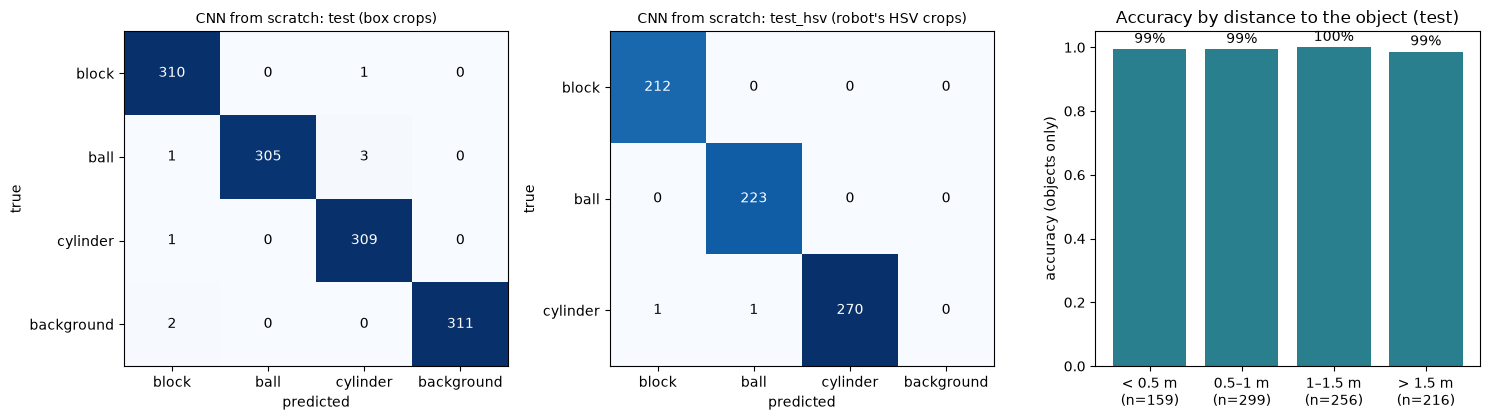

 < 0.5 m: 99.4%
 0.5–1 m: 99.3%
 1–1.5 m: 100.0%
 > 1.5 m: 98.6%


In [6]:
depth = np.array([float(r["depth_m"]) if r["depth_m"] else np.nan for r in rows_test])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, (cm, title, labels) in zip(axes[:2], [
        (confusion_matrix(y_test, pred, labels=range(4)), "test (box crops)", CLASSES),
        (confusion_matrix(y_hsv, pred_h, labels=range(4))[:3], "test_hsv (robot's HSV crops)", CLASSES)]):
    ax.imshow(cm, cmap="Blues", aspect="auto")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(4), CLASSES); ax.set_yticks(range(cm.shape[0]), labels[:cm.shape[0]])
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{best_name.replace('CNN: ', 'CNN ')}: {title}", fontsize=10)
bins = [(0, 0.5, "< 0.5 m"), (0.5, 1.0, "0.5–1 m"), (1.0, 1.5, "1–1.5 m"), (1.5, 9, "> 1.5 m")]
accs, labels_ = [], []
for lo, hi, lab in bins:
    m = (depth >= lo) & (depth < hi)
    accs.append((pred[m] == y_test[m]).mean()); labels_.append(f"{lab}\n(n={m.sum()})")
axes[2].bar(labels_, accs, color="#2A7F8E"); axes[2].set_ylim(0, 1.05); axes[2].set_ylabel("accuracy (objects only)")
for i, a in enumerate(accs): axes[2].text(i, a + 0.02, f"{a:.0%}", ha="center")
axes[2].set_title("Accuracy by distance to the object (test)")
plt.tight_layout(); fig.savefig(OUT / "shapes_confusion_distance.png", dpi=160); plt.show()
for (lo, hi, lab), a in zip(bins, accs): print(f"{lab:>8}: {a:.1%}")

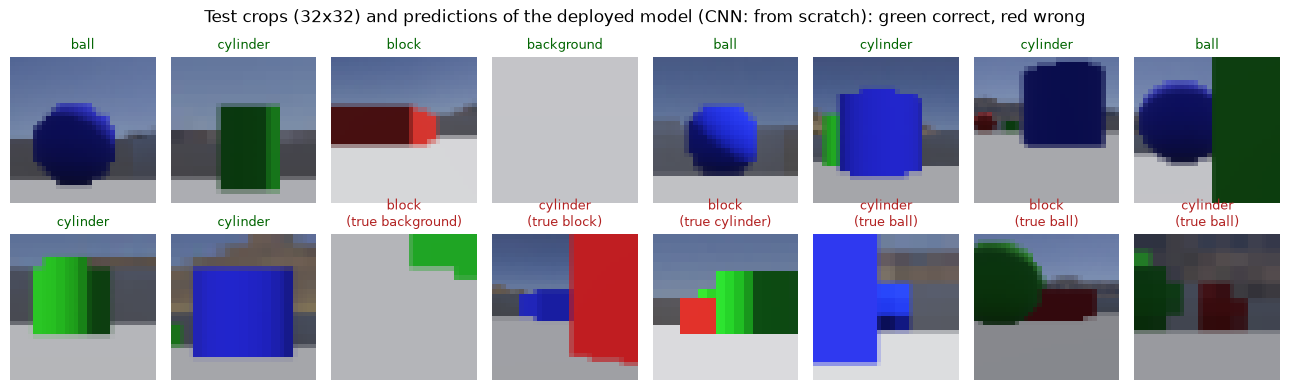

In [7]:
# Examples: correct and wrong test predictions
rng = np.random.default_rng(0)
wrong = np.where(pred != y_test)[0]; right = np.where(pred == y_test)[0]
pick = list(rng.choice(right, 16 - min(6, len(wrong)), replace=False)) + list(rng.choice(wrong, min(6, len(wrong)), replace=False))
fig, axes = plt.subplots(2, 8, figsize=(13, 4))
for ax, i in zip(axes.flat, pick):
    ax.imshow(x_test[i]); ax.axis("off")
    ok = pred[i] == y_test[i]
    ax.set_title(f"{CLASSES[pred[i]]}" + ("" if ok else f"\n(true {CLASSES[y_test[i]]})"), fontsize=9, color="darkgreen" if ok else "firebrick")
fig.suptitle(f"Test crops (32x32) and predictions of the deployed model ({best_name}): green correct, red wrong"); plt.tight_layout()
fig.savefig(OUT / "shapes_examples.png", dpi=160); plt.show()

## Deploy: int8 TensorFlow Lite for the robot

Same full-integer quantisation as the CIFAR-10 model, calibrated on 500 training crops.

In [8]:
def representative():
    for i in np.random.default_rng(1).choice(len(x_train), 500, replace=False):
        yield [x_train[i:i + 1]]
conv = tf.lite.TFLiteConverter.from_keras_model(best)
conv.optimizations = [tf.lite.Optimize.DEFAULT]; conv.representative_dataset = representative
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type = tf.int8; conv.inference_output_type = tf.int8
tfl = conv.convert()
pathlib.Path("results/models/webots_shapes_int8.tflite").write_bytes(tfl)
pathlib.Path("../webots_project/controllers/colour_detector/models/webots_shapes_int8.tflite").write_bytes(tfl)
best.save("results/models/webots_shapes.keras")

interp = tf.lite.Interpreter(model_content=tfl); interp.allocate_tensors()
IN, OD = interp.get_input_details()[0], interp.get_output_details()[0]
def int8_predict(x):
    s, z = IN["quantization"]
    interp.set_tensor(IN["index"], np.clip(np.round(x / s + z), -128, 127).astype(np.int8)[None]); interp.invoke()
    return int(np.argmax(interp.get_tensor(OD["index"])[0]))
t0 = time.perf_counter(); p8 = np.array([int8_predict(x) for x in x_test]); dt = (time.perf_counter() - t0) / len(x_test) * 1000
p8h = np.array([int8_predict(x) for x in x_hsv])
print(f"int8 model: {len(tfl) / 1024:.0f} kB, {dt:.3f} ms per image")
print(f"  test accuracy {(p8 == y_test).mean():.1%} (agreement with Keras {(p8 == pred).mean():.1%})")
print(f"  HSV-crop test accuracy {(p8h == y_hsv).mean():.1%}")

INFO:tensorflow:Assets written to: /var/folders/lw/r882xcn95f3dhmf7snjkn__00000gn/T/tmpmwjjdcoc/assets


INFO:tensorflow:Assets written to: /var/folders/lw/r882xcn95f3dhmf7snjkn__00000gn/T/tmpmwjjdcoc/assets


Saved artifact at '/var/folders/lw/r882xcn95f3dhmf7snjkn__00000gn/T/tmpmwjjdcoc'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 32, 32, 3), dtype=tf.float32, name='keras_tensor_227')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  5069998032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5069998800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5069998608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5069996496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5069999376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5069997072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5069998992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5069999184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5069996112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5070000336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5069999568: Tensor

/private/tmp/claude-501/-Users-krishnamahajan-Library-Application-Support-Claude-scratch-workspaces-7a395be2-a6ae-420e-83f5-80271cad5f7c-dee63cf5-31ea-4364-82fe-af1e63d02abf-scratch-2026-11-11-8f8053/5e048983-eb6f-413f-a49a-79271b128064/scratchpad/venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1794473809.777612 4878548 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1794473809.777620 4878548 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1794473809.777777 4878548 reader.cc:83] Reading SavedModel from: /var/folders/lw/r882xcn95f3dhmf7snjkn__00000gn/T/tmpmwjjdcoc
I0000 00:00:1794473809.778381 4878548 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1794473809.778384 4878548 reader.cc:147] Reading SavedModel debug info (if present) from: /var/folders/lw/r882xcn95f3dhmf7s

int8 model: 310 kB, 0.082 ms per image
  test accuracy 99.4% (agreement with Keras 100.0%)
  HSV-crop test accuracy 99.7%


fully_quantize: 0, inference_type: 6, input_inference_type: INT8, output_inference_type: INT8
W0000 00:00:1794473811.015228 4878548 flatbuffer_export.cc:3851] Skipping runtime version metadata in the model. This will be generated by the exporter.
/private/tmp/claude-501/-Users-krishnamahajan-Library-Application-Support-Claude-scratch-workspaces-7a395be2-a6ae-420e-83f5-80271cad5f7c-dee63cf5-31ea-4364-82fe-af1e63d02abf-scratch-2026-11-11-8f8053/5e048983-eb6f-413f-a49a-79271b128064/scratchpad/venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


## Summary

The table above compares five approaches on scenes none of them saw, with layout-level confidence intervals and three seeds each.
The robot's controller loads `webots_shapes_int8.tflite` next to the CIFAR-10 model, so every object it inspects is classified twice: by CIFAR-10 (which has no "block" class) and by this model.
The end-to-end test on the robot, with same-coloured distractors in the arena, is in `results/webots_runs/distractors/`.